<a href="https://colab.research.google.com/github/SheilandraZarawiba/PCVK_2026/blob/main/Week10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Praktikum Deteksi Obyek Dasar

In [5]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
import os

from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


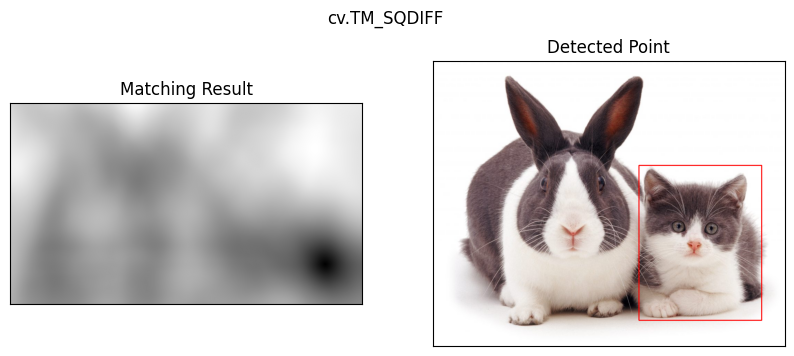

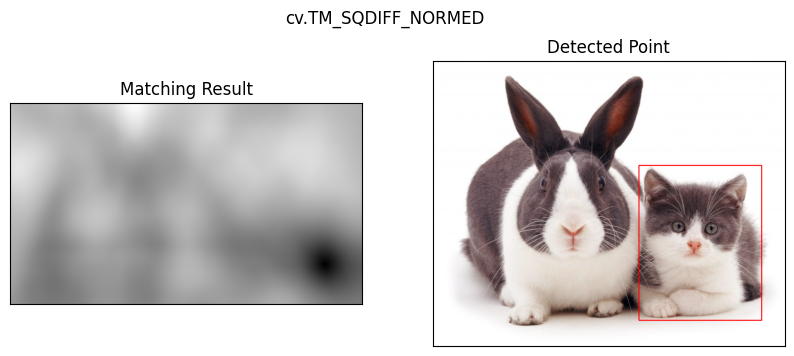

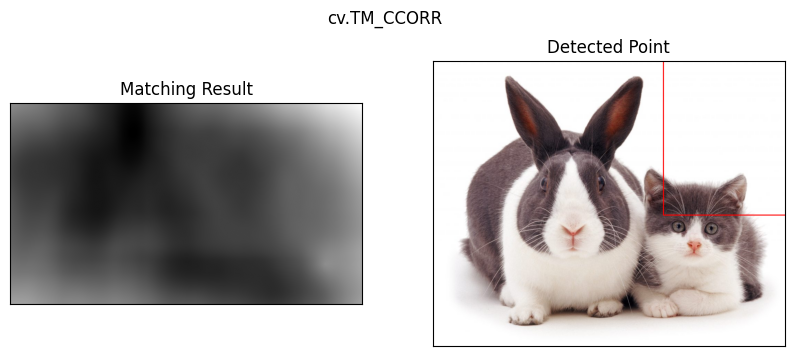

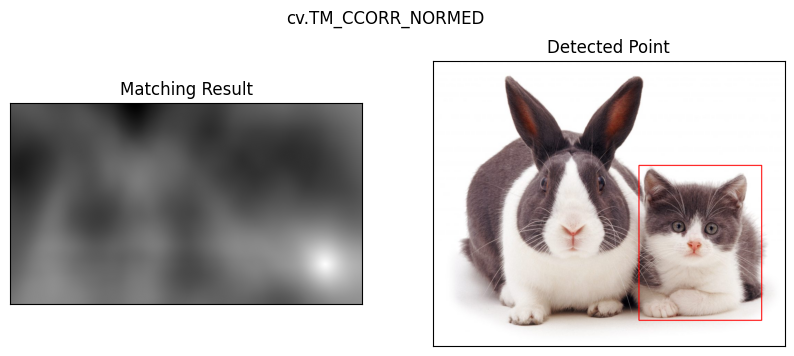

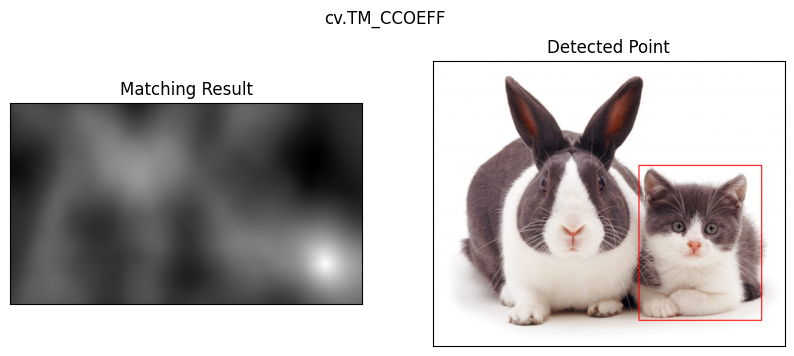

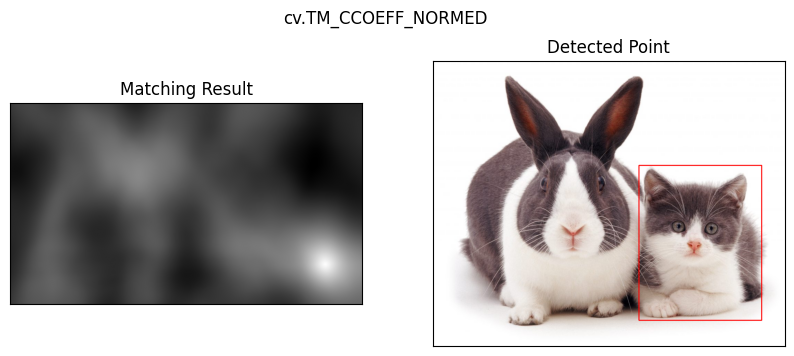

In [6]:
#Template Matching
img = cv.imread('/content/drive/MyDrive/PCVK/Gambar/cats_and_bunnies.jpg')
img2 = img.copy()
template = cv.imread('/content/drive/MyDrive/PCVK/Gambar/cat2_templatejpg.jpg')
w, h = template.shape[1], template.shape[0]

methods = ['cv.TM_SQDIFF', 'cv.TM_SQDIFF_NORMED',
           'cv.TM_CCORR', 'cv.TM_CCORR_NORMED',
           'cv.TM_CCOEFF', 'cv.TM_CCOEFF_NORMED']

for meth in methods:
    img = img2.copy()
    method = eval(meth)

    res = cv.matchTemplate(img, template, method)
    min_val, max_val, min_loc, max_loc = cv.minMaxLoc(res)

    if method in [cv.TM_SQDIFF, cv.TM_SQDIFF_NORMED]:
        top_left = min_loc
    else:
        top_left = max_loc

    bottom_right = (top_left[0] + w, top_left[1] + h)
    cv.rectangle(img, top_left, bottom_right, (0, 0, 255), 2)

    plt.figure(figsize=(10, 4))
    plt.subplot(1, 2, 1)
    plt.imshow(res, cmap='gray')
    plt.title('Matching Result')
    plt.xticks([])
    plt.yticks([])

    plt.subplot(1, 2, 2)
    plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
    plt.title('Detected Point')
    plt.xticks([])
    plt.yticks([])

    plt.suptitle(meth)
    plt.show()

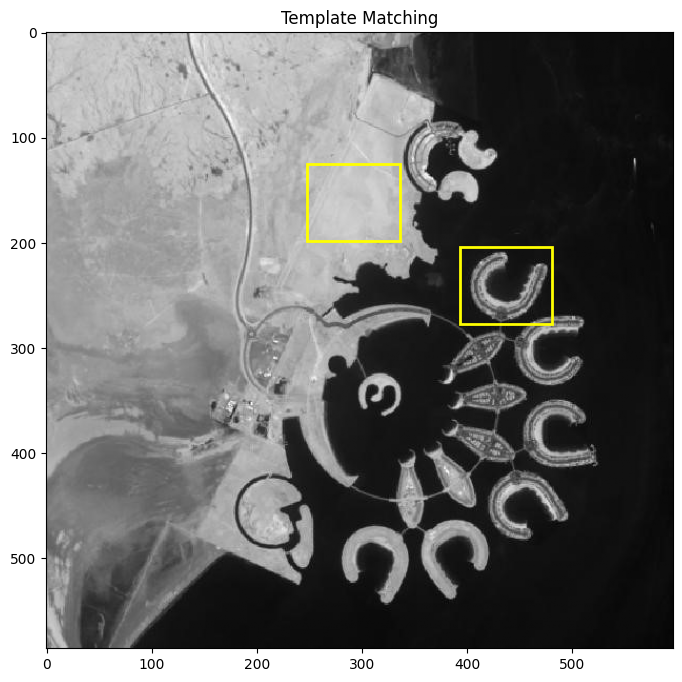

Jumlah titik terdeteksi: 2


In [7]:
# Template Matching tanpa OpenCV
from PIL import Image
from skimage.feature import match_template, peak_local_max
from matplotlib.patches import Rectangle

img = np.array(Image.open('/content/drive/MyDrive/PCVK/Gambar/bahrain.jpg').convert('L'))
template = np.array(Image.open('/content/drive/MyDrive/PCVK/Gambar/bahrain-template.jpg').convert('L'))

result = match_template(img, template)

coordinates = peak_local_max(
    result,
    min_distance=template.shape[0],
    threshold_abs=0.4,
    num_peaks=20
)

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(img, cmap='gray')

for y, x in coordinates:
    ax.add_patch(Rectangle(
        (x, y),
        template.shape[1],
        template.shape[0],
        edgecolor='yellow',
        facecolor='none',
        linewidth=2
    ))

ax.set_title('Template Matching')
plt.show()

print("Jumlah titik terdeteksi:", len(coordinates))

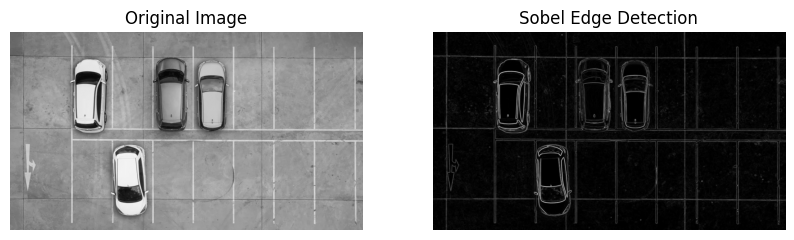

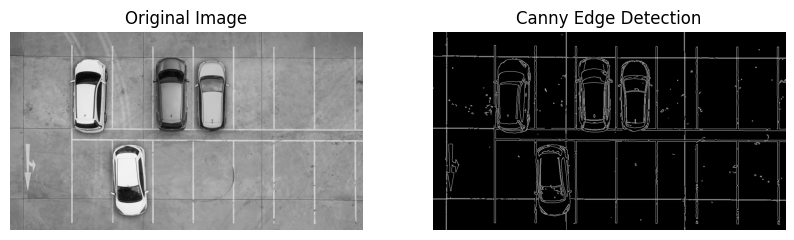

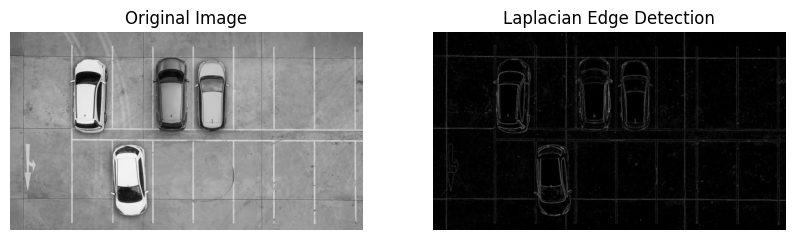

In [8]:
# Sobel Edge Detection, Canny Edge Detection, dan Laplacian Edge Detection

img = cv.imread('/content/drive/MyDrive/PCVK/Gambar/car-park.jpg', 0)

# Sobel Edge Detection
sobelx = cv.Sobel(img, cv.CV_64F, 1, 0, ksize=3)
sobely = cv.Sobel(img, cv.CV_64F, 0, 1, ksize=3)
sobel = cv.magnitude(sobelx, sobely)

plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.imshow(img, cmap='gray')
plt.title('Original Image')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(sobel, cmap='gray')
plt.title('Sobel Edge Detection')
plt.axis('off')
plt.show()


# Canny Edge Detection
canny = cv.Canny(img, 100, 200)

plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.imshow(img, cmap='gray')
plt.title('Original Image')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(canny, cmap='gray')
plt.title('Canny Edge Detection')
plt.axis('off')
plt.show()


# Laplacian Edge Detection
laplacian = cv.Laplacian(img, cv.CV_64F)

plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.imshow(img, cmap='gray')
plt.title('Original Image')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(np.abs(laplacian), cmap='gray')
plt.title('Laplacian Edge Detection')
plt.axis('off')
plt.show()

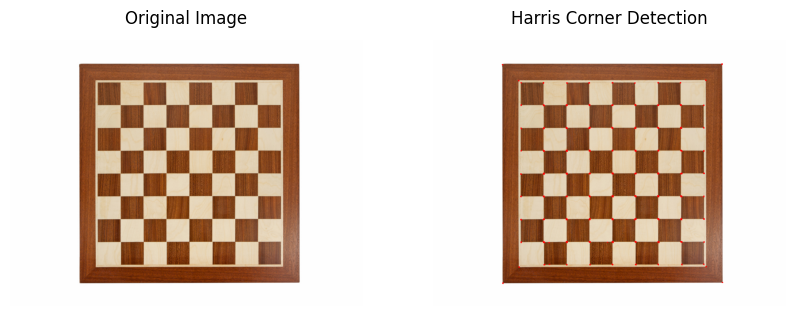

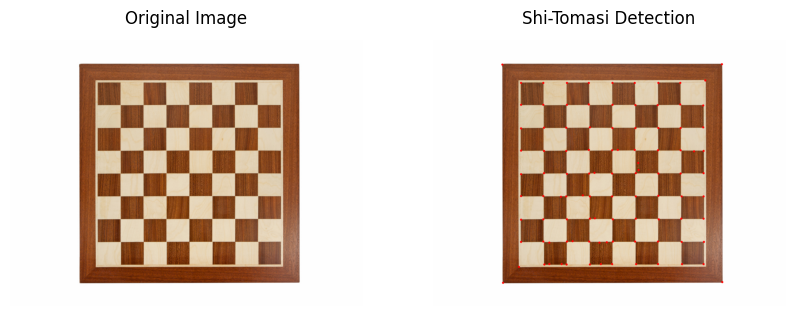

In [9]:
# Harris Corner Detection dan Shi-Tomasi Detection

img = cv.imread('/content/drive/MyDrive/PCVK/Gambar/chess-board.jpg')
gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

# Harris Corner Detection
gray = np.float32(gray)
dst = cv.cornerHarris(gray, 2, 3, 0.04)
dst = cv.dilate(dst, None)

img_harris = img.copy()
img_harris[dst > 0.01 * dst.max()] = [0, 0, 255]

plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
plt.title('Original Image')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(cv.cvtColor(img_harris, cv.COLOR_BGR2RGB))
plt.title('Harris Corner Detection')
plt.axis('off')
plt.show()


# Shi-Tomasi Detection
img = cv.imread('/content/drive/MyDrive/PCVK/Gambar/chess-board.jpg')
gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

corners = cv.goodFeaturesToTrack(gray, 100, 0.01, 10)
corners = np.intp(corners)

img_shi = img.copy()

for corner in corners:
    x, y = corner.ravel()
    cv.circle(img_shi, (x, y), 3, (0, 0, 255), -1)

plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
plt.title('Original Image')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(cv.cvtColor(img_shi, cv.COLOR_BGR2RGB))
plt.title('Shi-Tomasi Detection')
plt.axis('off')
plt.show()

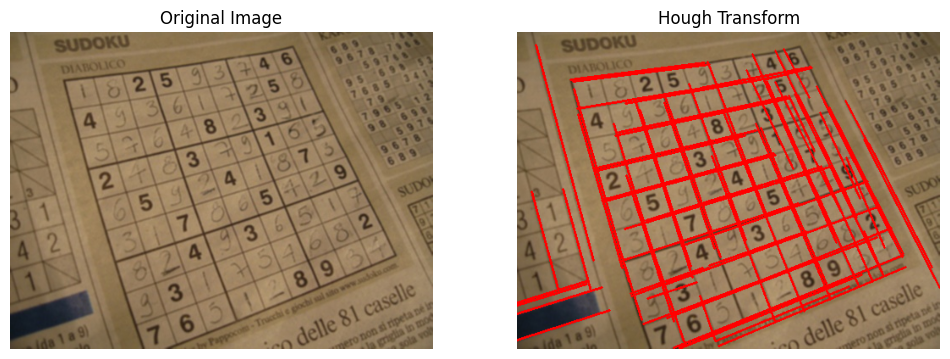

In [10]:
# Hough Transform

img = cv.imread('/content/drive/MyDrive/PCVK/Gambar/sudoku.jpg')
gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

# Thresholding
edges = cv.Canny(gray, 50, 150, apertureSize=3)

# Hough Line Transform
lines = cv.HoughLinesP(
    edges,
    1,
    np.pi / 180,
    threshold=100,
    minLineLength=50,
    maxLineGap=10
)

img_hough = img.copy()

if lines is not None:
    for line in lines:
        x1, y1, x2, y2 = line[0]
        cv.line(img_hough, (x1, y1), (x2, y2), (0, 0, 255), 2)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
plt.title('Original Image')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(cv.cvtColor(img_hough, cv.COLOR_BGR2RGB))
plt.title('Hough Transform')
plt.axis('off')

plt.show()

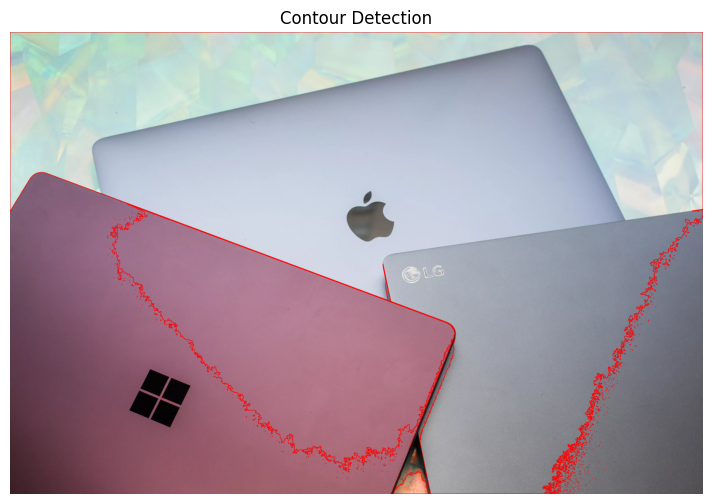

In [11]:
# Contour Detection

img = cv.imread('/content/drive/MyDrive/PCVK/Gambar/laptop.jpg')
imgray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

ret, thresh = cv.threshold(imgray, 127, 255, cv.THRESH_BINARY)

contours, hierarchy = cv.findContours(
    thresh,
    cv.RETR_EXTERNAL,
    cv.CHAIN_APPROX_SIMPLE
)

img_contours = img.copy()
cv.drawContours(img_contours, contours, -1, (0, 0, 255), 2)

plt.figure(figsize=(10, 6))
plt.imshow(cv.cvtColor(img_contours, cv.COLOR_BGR2RGB))
plt.title('Contour Detection')
plt.axis('off')
plt.show()

Praktikum Feature Matching dan Face Detection

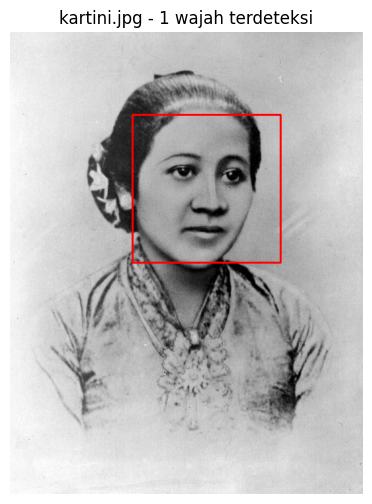

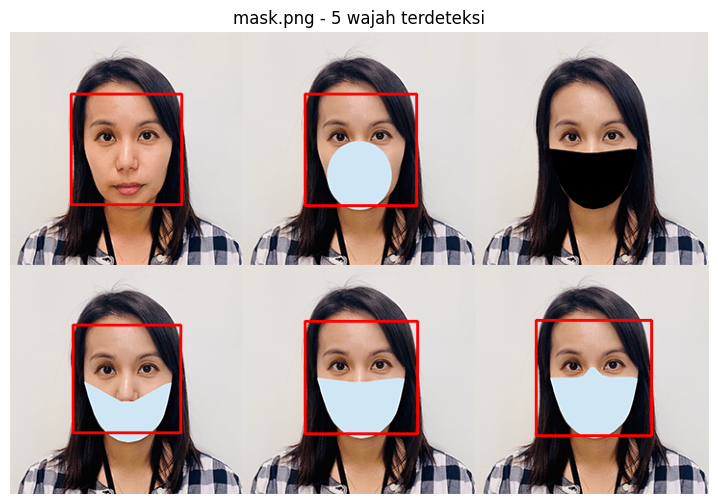

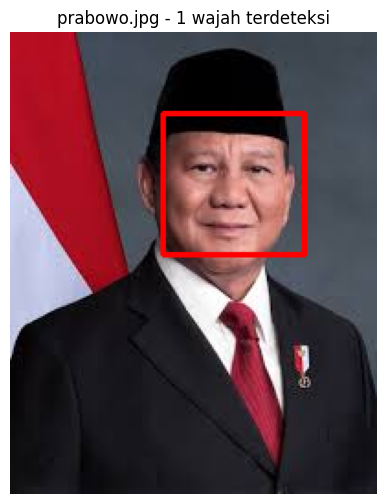

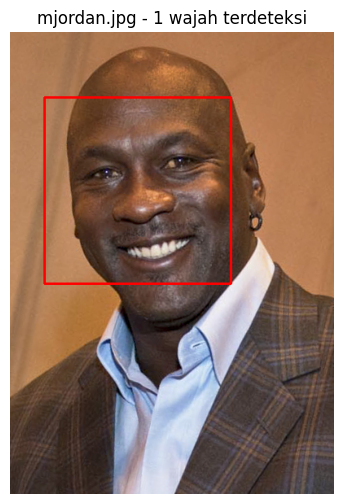

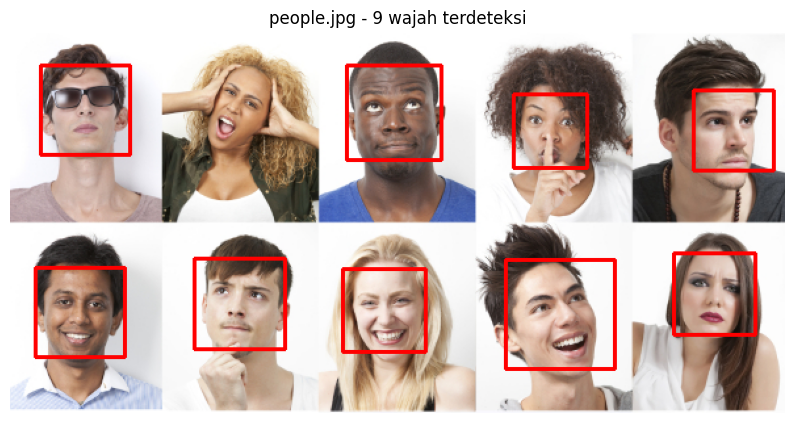

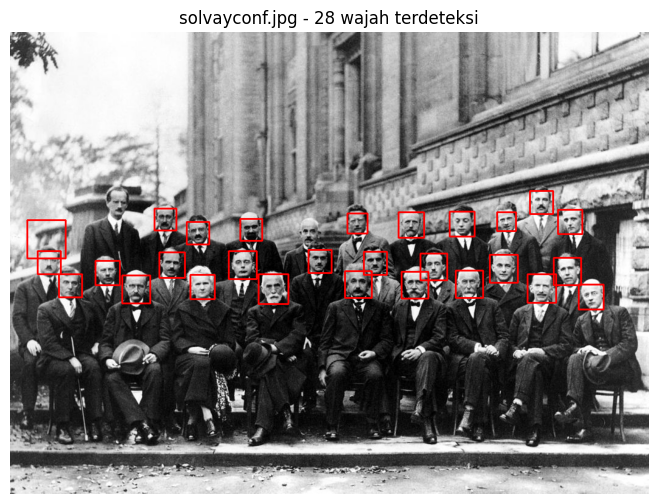

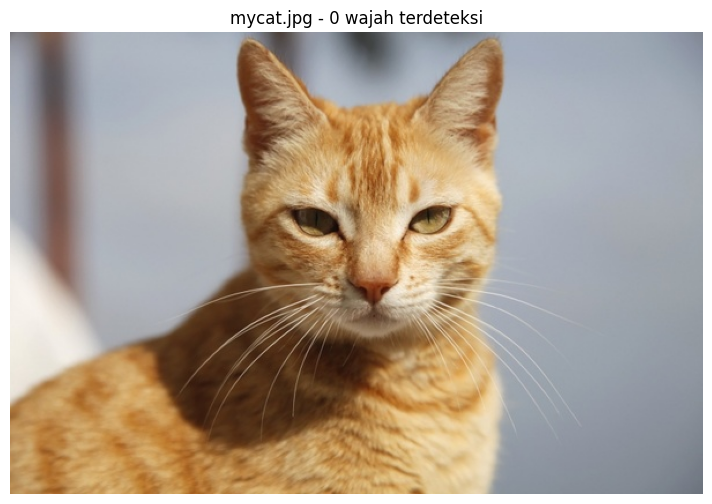

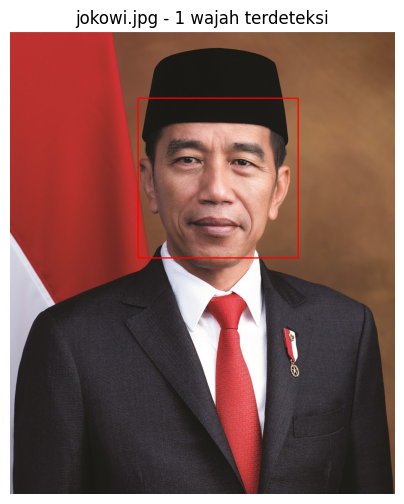

In [12]:
import os
import glob
folder = '/content/drive/MyDrive/PCVK/Gambar/facedet'
files = glob.glob(folder + '/*')

images = [f for f in files if f.lower().endswith(('.jpg', '.jpeg', '.png'))]

face_cascade = cv.CascadeClassifier(
    cv.data.haarcascades + 'haarcascade_frontalface_alt.xml'
)

for file in images:
    img = cv.imread(file)

    if img is None:
        continue

    gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)
    faces = face_cascade.detectMultiScale(gray)

    img_faces = img.copy()

    for (x, y, w, h) in faces:
        cv.rectangle(img_faces, (x, y), (x + w, y + h), (0, 0, 255), 2)

    plt.figure(figsize=(10, 6))
    plt.imshow(cv.cvtColor(img_faces, cv.COLOR_BGR2RGB))
    plt.title(os.path.basename(file) + ' - ' + str(len(faces)) + ' wajah terdeteksi')
    plt.axis('off')
    plt.show()

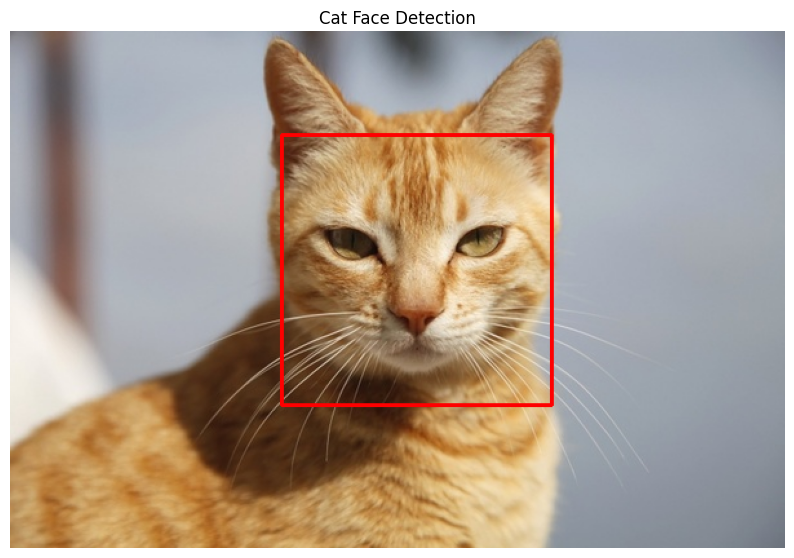

Jumlah wajah kucing terdeteksi: 1


In [13]:
# Cat Face Detection

!wget -q -O haarcascade_frontalcatface.xml https://raw.githubusercontent.com/opencv/opencv/master/data/haarcascades/haarcascade_frontalcatface.xml

cat_cascade = cv.CascadeClassifier('haarcascade_frontalcatface.xml')

img = cv.imread('/content/drive/MyDrive/PCVK/Gambar/facedet/mycat.jpg')
gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

cats = cat_cascade.detectMultiScale(gray, 1.1, 3)

img_cat = img.copy()

for (x, y, w, h) in cats:
    cv.rectangle(img_cat, (x, y), (x + w, y + h), (0, 0, 255), 2)

plt.figure(figsize=(10, 8))
plt.imshow(cv.cvtColor(img_cat, cv.COLOR_BGR2RGB))
plt.title('Cat Face Detection')
plt.axis('off')
plt.show()

print('Jumlah wajah kucing terdeteksi:', len(cats))

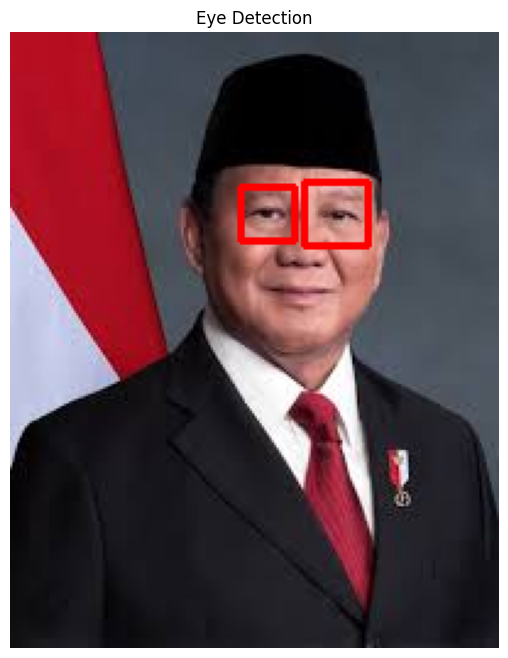

Jumlah mata terdeteksi: 2


In [14]:
# Eye Detection

eye_cascade = cv.CascadeClassifier(
    cv.data.haarcascades + 'haarcascade_eye.xml'
)

img = cv.imread('/content/drive/MyDrive/PCVK/Gambar/facedet/prabowo.jpg')
gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

eyes = eye_cascade.detectMultiScale(gray, 1.1, 5)

img_eyes = img.copy()

for (x, y, w, h) in eyes:
    cv.rectangle(img_eyes, (x, y), (x + w, y + h), (0, 0, 255), 2)

plt.figure(figsize=(10, 8))
plt.imshow(cv.cvtColor(img_eyes, cv.COLOR_BGR2RGB))
plt.title('Eye Detection')
plt.axis('off')
plt.show()

print('Jumlah mata terdeteksi:', len(eyes))

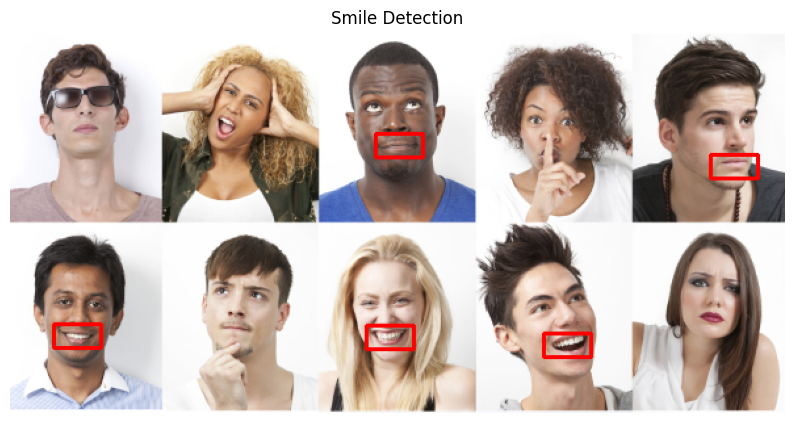

Jumlah senyum terdeteksi: 5


In [15]:
# Smile Detection

smile_cascade = cv.CascadeClassifier(
    cv.data.haarcascades + 'haarcascade_smile.xml'
)

img = cv.imread('/content/drive/MyDrive/PCVK/Gambar/facedet/people.jpg')

gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)
gray = cv.equalizeHist(gray)

smiles = smile_cascade.detectMultiScale(
    gray,
    scaleFactor=1.7,
    minNeighbors=5,
    minSize=(15, 15)
)

img_smile = img.copy()

for (x, y, w, h) in smiles:
    cv.rectangle(img_smile, (x, y), (x + w, y + h), (0, 0, 255), 2)

plt.figure(figsize=(10, 8))
plt.imshow(cv.cvtColor(img_smile, cv.COLOR_BGR2RGB))
plt.title('Smile Detection')
plt.axis('off')
plt.show()

print('Jumlah senyum terdeteksi:', len(smiles))

<IPython.core.display.Javascript object>

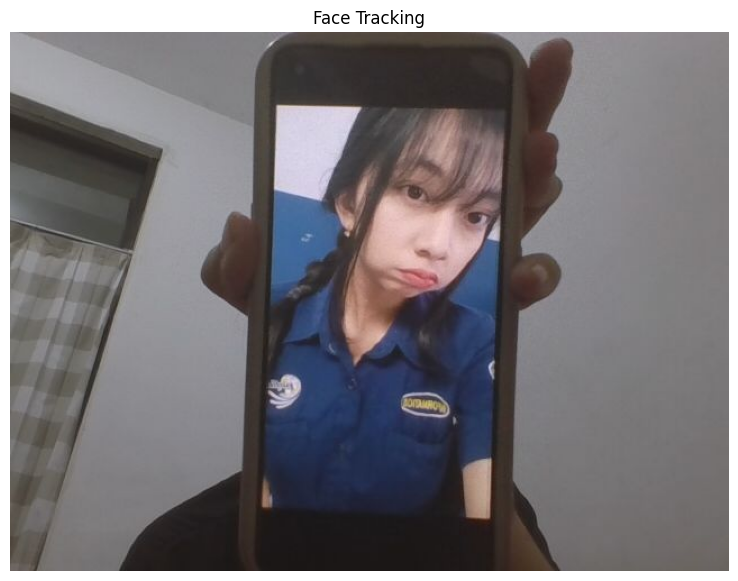

In [18]:
# Face Tracking menggunakan Google Colab

from IPython.display import display, Javascript
from google.colab.output import eval_js
from base64 import b64decode
from IPython.display import Image
import cv2 as cv
import numpy as np
import PIL.Image
import io

def take_photo():
    js = Javascript('''
        async function takePhoto() {
            const div = document.createElement('div');
            const video = document.createElement('video');
            const button = document.createElement('button');
            button.textContent = 'Ambil Foto';
            div.appendChild(video);
            div.appendChild(button);
            document.body.appendChild(div);

            const stream = await navigator.mediaDevices.getUserMedia({video: true});
            video.srcObject = stream;
            video.style.transform = 'scaleX(-1)';
            await video.play();

            await new Promise((resolve) => button.onclick = resolve);

            const canvas = document.createElement('canvas');
            canvas.width = video.videoWidth;
            canvas.height = video.videoHeight;
            canvas.getContext('2d').drawImage(video, 0, 0);

            stream.getTracks().forEach(track => track.stop());
            div.remove();

            return canvas.toDataURL('image/jpeg', 0.8);
        }
    ''')
    display(js)
    data = eval_js('takePhoto()')
    return b64decode(data.split(',')[1])

# Mengambil gambar dari kamera
image_bytes = take_photo()
image = PIL.Image.open(io.BytesIO(image_bytes))
img = cv.cvtColor(np.array(image), cv.COLOR_RGB2BGR)

# Deteksi wajah
face_cascade = cv.CascadeClassifier(
    cv.data.haarcascades + 'haarcascade_frontalface_default.xml'
)

gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)
faces = face_cascade.detectMultiScale(gray, 1.1, 5)

for (x, y, w, h) in faces:
    cv.rectangle(img, (x, y), (x + w, y + h), (0, 255, 0), 2)

plt.figure(figsize=(10, 7))
plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
plt.title('Face Tracking')
plt.axis('off')
plt.show()

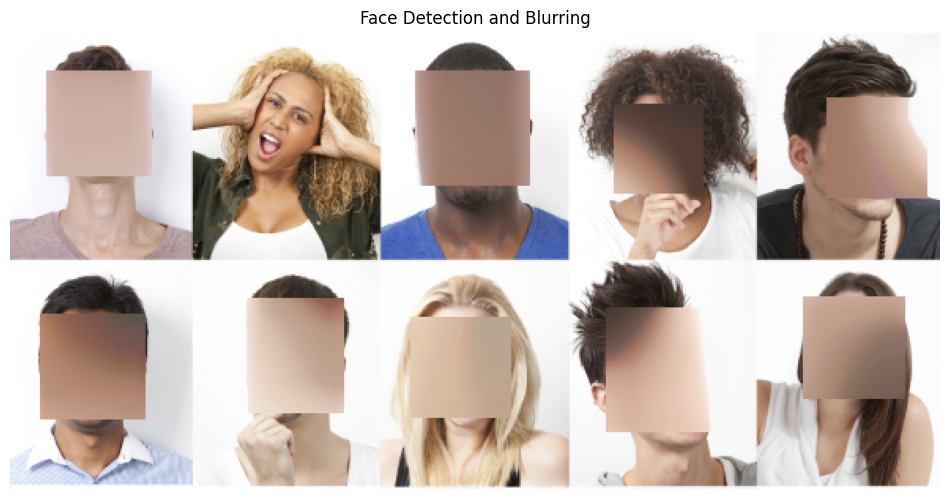

Jumlah wajah terdeteksi: 9


In [19]:
# Face Detection dan Blurring

face_cascade = cv.CascadeClassifier(
    cv.data.haarcascades + 'haarcascade_frontalface_default.xml'
)

img = cv.imread('/content/drive/MyDrive/PCVK/Gambar/facedet/people.jpg')
gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

faces = face_cascade.detectMultiScale(gray, 1.1, 5)

img_blur = img.copy()

for (x, y, w, h) in faces:
    face = img_blur[y:y+h, x:x+w]
    img_blur[y:y+h, x:x+w] = cv.medianBlur(face, 99)

plt.figure(figsize=(12, 8))
plt.imshow(cv.cvtColor(img_blur, cv.COLOR_BGR2RGB))
plt.title('Face Detection and Blurring')
plt.axis('off')
plt.show()

print('Jumlah wajah terdeteksi:', len(faces))

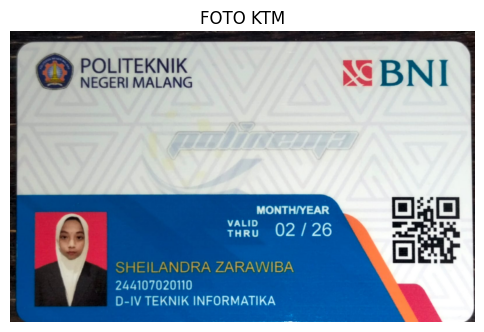

In [20]:
# Menampilkan Foto KTM

img_ktm = cv.imread('/content/drive/MyDrive/PCVK/Gambar/ktm.jpg')

img_ktm_rgb = cv.cvtColor(img_ktm, cv.COLOR_BGR2RGB)

plt.figure(figsize=(6, 8))
plt.imshow(img_ktm_rgb)
plt.title('FOTO KTM')
plt.axis('off')
plt.show()

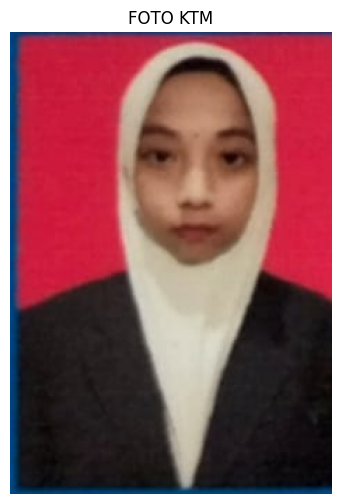

In [21]:
# Soal 14b: Menampilkan Foto KTM

img_ktm = cv.imread('/content/drive/MyDrive/PCVK/Gambar/ktm.jpg')

# Crop bagian foto pada KTM
foto_ktm = img_ktm[620:950, 80:310]

# Tampilkan hasil crop
foto_ktm_rgb = cv.cvtColor(foto_ktm, cv.COLOR_BGR2RGB)

plt.figure(figsize=(5, 6))
plt.imshow(foto_ktm_rgb)
plt.title('FOTO KTM')
plt.axis('off')
plt.show()

Jumlah fitur KTM: 1000
Jumlah fitur target: 1000


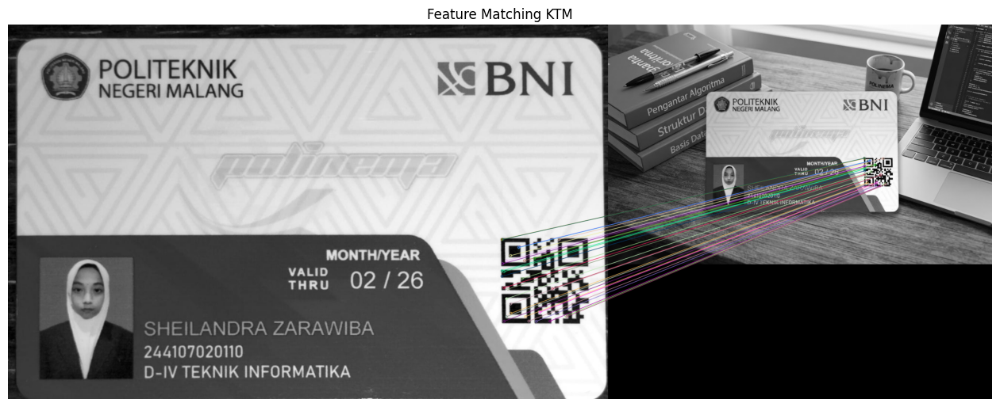

In [22]:
# Deteksi Objek KTM menggunakan Feature Matching

img1 = cv.imread('/content/drive/MyDrive/PCVK/Gambar/ktm.jpg', 0)
img2 = cv.imread('/content/drive/MyDrive/PCVK/Gambar/ktm_target.jpg', 0)

# Periksa apakah gambar berhasil dibaca
if img1 is None or img2 is None:
    print("Gambar KTM atau gambar target tidak ditemukan. Periksa path file.")
else:
    # Deteksi fitur menggunakan ORB
    orb = cv.ORB_create(nfeatures=1000)

    kp1, des1 = orb.detectAndCompute(img1, None)
    kp2, des2 = orb.detectAndCompute(img2, None)

    print("Jumlah fitur KTM:", len(kp1))
    print("Jumlah fitur target:", len(kp2))

    if des1 is None or des2 is None:
        print("Fitur tidak ditemukan pada salah satu gambar.")
    else:
        # Mencocokkan fitur kedua gambar
        bf = cv.BFMatcher(cv.NORM_HAMMING, crossCheck=True)
        matches = bf.match(des1, des2)

        # Mengurutkan hasil berdasarkan jarak
        matches = sorted(matches, key=lambda x: x.distance)

        # Menampilkan hasil pencocokan
        img_matches = cv.drawMatches(
            img1, kp1,
            img2, kp2,
            matches[:30],
            None,
            flags=cv.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
        )

        plt.figure(figsize=(16, 8))
        plt.imshow(img_matches, cmap='gray')
        plt.title('Feature Matching KTM')
        plt.axis('off')
        plt.show()

Tugas Pengayaan : Pengenalan Karakter KTM dengan CNN

In [23]:
import zipfile
import os

zip_path = '/content/drive/MyDrive/PCVK/Gambar/num.zip'
extract_path = '/content/drive/MyDrive/PCVK/Gambar/'

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Ekstraksi selesai!")

Ekstraksi selesai!


In [24]:
!ls "/content/drive/MyDrive/PCVK/Gambar/num"

0  1  2  3  4  5  6  7	8  9


In [25]:
dataset_path = '/content/drive/MyDrive/PCVK/Gambar/num'

In [26]:
import os
import cv2
import random
import numpy as np
import pickle
from tqdm import tqdm

DATADIR = "/content/drive/MyDrive/PCVK/Gambar/num"
width, height = 100, 100

dirs = sorted(os.listdir(DATADIR))
training_data = []

for char_name in dirs:
    path = os.path.join(DATADIR, char_name)
    class_number = dirs.index(char_name)

    for img in tqdm(os.listdir(path), desc=char_name):
        try:
            img_array = cv2.imread(
                os.path.join(path, img),
                cv2.IMREAD_GRAYSCALE
            )
            new_array = cv2.resize(img_array, (width, height))
            training_data.append([new_array, class_number])
        except Exception:
            pass

random.shuffle(training_data)

X, Y = [], []

for feature, label in training_data:
    X.append(feature)
    Y.append(label)

X = np.array(X).reshape(-1, width, height, 1)
Y = np.array(Y)

pickle.dump(X, open("X.pickle", "wb"))
pickle.dump(Y, open("Y.pickle", "wb"))
pickle.dump(dirs, open("kelas.pickle", "wb"))

print("jumlah data :", len(training_data))
print("jumlah kelas:", len(dirs), dirs)

9: 100%|██████████| 1105/1105 [00:05<00:00, 199.42it/s]


jumlah data : 11303
jumlah kelas: 10 ['0', '1', '2', '3', '4', '5', '6', '7', '8', '9']


In [27]:
import pickle
from keras.layers import (
    Input, Conv2D, MaxPooling2D,
    Flatten, Dense, ZeroPadding2D
)
from keras.models import Model
from keras.optimizers import Adam
from keras.utils import to_categorical

X = pickle.load(open("X.pickle", "rb"))
Y = pickle.load(open("Y.pickle", "rb"))

Y = to_categorical(Y)
X = X / 255.0

width, height = 100, 100
jumlah_kelas = Y.shape[1]

inputs = Input(shape=(width, height, 1))

conv_layer = ZeroPadding2D(padding=(2, 2))(inputs)
conv_layer = Conv2D(
    16, (5, 5), strides=(1, 1), activation='relu'
)(conv_layer)
conv_layer = MaxPooling2D((2, 2))(conv_layer)

conv_layer = Conv2D(
    32, (3, 3), strides=(1, 1), activation='relu'
)(conv_layer)
conv_layer = Conv2D(
    32, (3, 3), strides=(1, 1), activation='relu'
)(conv_layer)
conv_layer = MaxPooling2D((2, 2))(conv_layer)

conv_layer = Conv2D(
    64, (3, 3), strides=(1, 1), activation='relu'
)(conv_layer)

flaten = Flatten()(conv_layer)
fc_layer = Dense(256, activation='relu')(flaten)
fc_layer = Dense(64, activation='relu')(fc_layer)

outputs = Dense(jumlah_kelas, activation='softmax')(fc_layer)

model = Model(inputs=inputs, outputs=outputs)

model.compile(
    optimizer=Adam(learning_rate=0.0001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

riwayat = model.fit(
    X, Y,
    epochs=20,
    verbose=1,
    validation_split=0.2
)

model.save('anpr.keras')

print("akurasi training   :", riwayat.history['accuracy'][-1])
print("akurasi validasi   :", riwayat.history['val_accuracy'][-1])

Epoch 1/20
283/283 ━━━━━━━━━━━━━━━━━━━━ 178s 619ms/step - accuracy: 0.7461 - loss: 0.8193 - val_accuracy: 0.8837 - val_loss: 0.3739
Epoch 2/20
283/283 ━━━━━━━━━━━━━━━━━━━━ 195s 598ms/step - accuracy: 0.9038 - loss: 0.3000 - val_accuracy: 0.9151 - val_loss: 0.2638
Epoch 3/20
283/283 ━━━━━━━━━━━━━━━━━━━━ 180s 637ms/step - accuracy: 0.9394 - loss: 0.1972 - val_accuracy: 0.9381 - val_loss: 0.2113
Epoch 4/20
283/283 ━━━━━━━━━━━━━━━━━━━━ 196s 613ms/step - accuracy: 0.9616 - loss: 0.1316 - val_accuracy: 0.9505 - val_loss: 0.1847
Epoch 5/20
283/283 ━━━━━━━━━━━━━━━━━━━━ 169s 598ms/step - accuracy: 0.9728 - loss: 0.0919 - val_accuracy: 0.9549 - val_loss: 0.1627
Epoch 6/20
283/283 ━━━━━━━━━━━━━━━━━━━━ 203s 600ms/step - accuracy: 0.9822 - loss: 0.0651 - val_accuracy: 0.9611 - val_loss: 0.1468
Epoch 7/20
283/283 ━━━━━━━━━━━━━━━━━━━━ 200s 596ms/step - accuracy: 0.9879 - loss: 0.0434 - val_accuracy: 0.9611 - val_loss: 0.1452
Epoch 8/20
283/283 ━━━━━━━━━━━━━━━━━━━━ 199s 585ms/step - accuracy: 0.9938 -

In [28]:
import shutil

shutil.copy(
    '/content/anpr.keras',
    '/content/drive/MyDrive/PCVK/Gambar/anpr.keras'
)

shutil.copy(
    '/content/kelas.pickle',
    '/content/drive/MyDrive/PCVK/Gambar/kelas.pickle'
)

print("Model dan kelas berhasil disimpan ke Google Drive.")

Model dan kelas berhasil disimpan ke Google Drive.


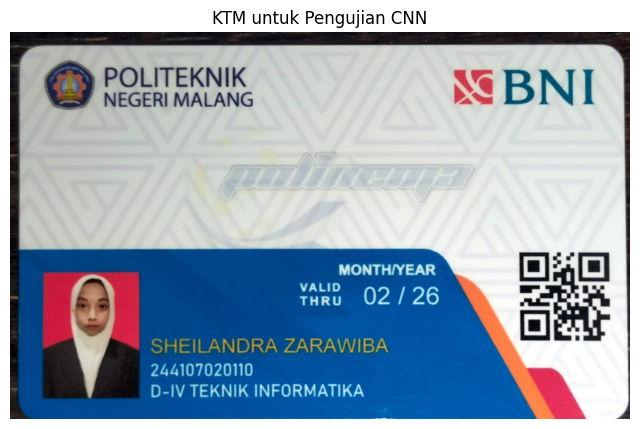

In [29]:
import cv2
import matplotlib.pyplot as plt

img_ktm = cv2.imread('/content/drive/MyDrive/PCVK/Gambar/ktm.jpg')

img_ktm_rgb = cv2.cvtColor(img_ktm, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(8, 10))
plt.imshow(img_ktm_rgb)
plt.title('KTM untuk Pengujian CNN')
plt.axis('off')
plt.show()

In [30]:
import os

testing_path = '/content/drive/MyDrive/PCVK/Gambar/testing/ktm'

os.makedirs(testing_path, exist_ok=True)

print("Folder testing berhasil dibuat:", testing_path)

Folder testing berhasil dibuat: /content/drive/MyDrive/PCVK/Gambar/testing/ktm


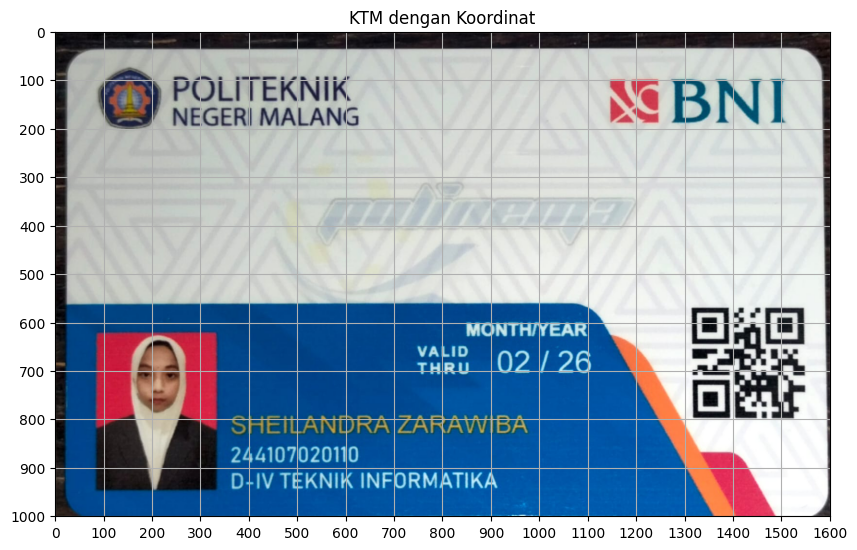

In [32]:
import cv2
import matplotlib.pyplot as plt

path_ktm = '/content/drive/MyDrive/PCVK/Gambar/ktm.jpg'
img_ktm = cv2.imread(path_ktm)
img_rgb = cv2.cvtColor(img_ktm, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(10, 12))
plt.imshow(img_rgb)
plt.xticks(range(0, 1601, 100))
plt.yticks(range(0, 1001, 100))
plt.grid()
plt.title('KTM dengan Koordinat')
plt.show()

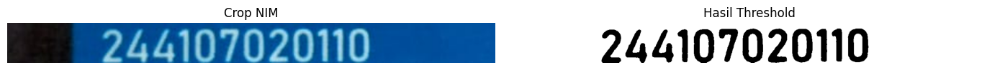

In [38]:
import cv2
import matplotlib.pyplot as plt

path_ktm = '/content/drive/MyDrive/PCVK/Gambar/ktm.jpg'
img = cv2.imread(path_ktm)

# Crop area NIM berdasarkan koordinat yang sudah ditemukan
nim = img[850:890, 270:750]

# Perbesar gambar agar digit lebih mudah diproses
nim = cv2.resize(nim, None, fx=3, fy=3, interpolation=cv2.INTER_CUBIC)

gray = cv2.cvtColor(nim, cv2.COLOR_BGR2GRAY)

# Binarisasi untuk memperjelas karakter
_, thresh = cv2.threshold(
    gray, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU
)

plt.figure(figsize=(14, 4))

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(nim, cv2.COLOR_BGR2RGB))
plt.title('Crop NIM')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(thresh, cmap='gray')
plt.title('Hasil Threshold')
plt.axis('off')

plt.tight_layout()
plt.show()

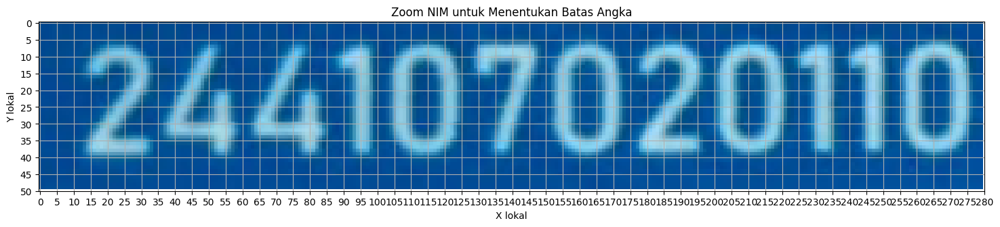

In [45]:
import cv2
import matplotlib.pyplot as plt

img = cv2.imread('/content/drive/MyDrive/PCVK/Gambar/ktm.jpg')

# Area NIM pada gambar KTM
crop = img[850:900, 350:630]
crop = cv2.cvtColor(crop, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(18, 4))
plt.imshow(crop)
plt.xticks(range(0, crop.shape[1] + 1, 5))
plt.yticks(range(0, crop.shape[0] + 1, 5))
plt.grid(True)
plt.title('Zoom NIM untuk Menentukan Batas Angka')
plt.xlabel('X lokal')
plt.ylabel('Y lokal')
plt.show()

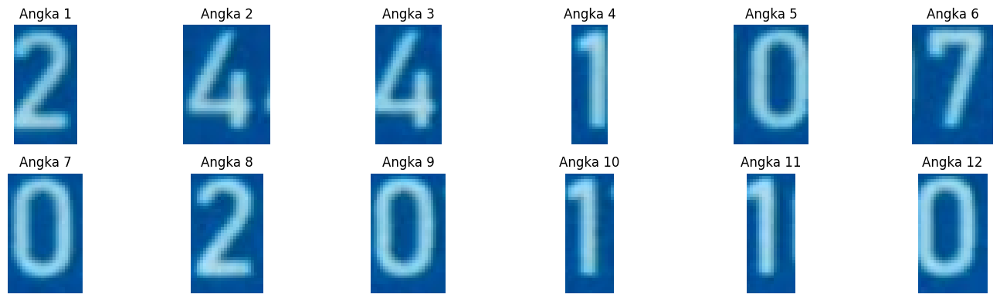

In [46]:
import cv2
import matplotlib.pyplot as plt

img = cv2.imread('/content/drive/MyDrive/PCVK/Gambar/ktm.jpg')

# Crop zoom dimulai dari koordinat asli X=350, Y=850
crop = img[850:900, 350:630]

batas_x = [
    (15, 36), (36, 65), (65, 87), (87, 99),
    (99, 124), (124, 151), (151, 176), (176, 200),
    (200, 225), (225, 241), (241, 257), (257, 280)
]

fig, axes = plt.subplots(2, 6, figsize=(15, 4))

for i, (x1, x2) in enumerate(batas_x):
    digit = crop[5:45, x1:x2]
    digit = cv2.cvtColor(digit, cv2.COLOR_BGR2RGB)

    ax = axes[i // 6, i % 6]
    ax.imshow(digit)
    ax.set_title(f'Angka {i+1}')
    ax.axis('off')

plt.tight_layout()
plt.show()

In [47]:
import os
import cv2

path_ktm = '/content/drive/MyDrive/PCVK/Gambar/ktm.jpg'
folder_testing = '/content/drive/MyDrive/PCVK/Gambar/testing/ktm'

img = cv2.imread(path_ktm)

# Crop area NIM dari KTM
crop = img[850:900, 350:630]

batas_x = [
    (15, 36), (36, 65), (65, 87), (87, 99),
    (99, 124), (124, 151), (151, 176), (176, 200),
    (200, 225), (225, 241), (241, 257), (257, 280)
]

os.makedirs(folder_testing, exist_ok=True)

for i, (x1, x2) in enumerate(batas_x, start=1):
    digit = crop[5:45, x1:x2]
    digit = cv2.resize(digit, (100, 100))

    nama_file = os.path.join(folder_testing, f'{i:02d}.jpg')
    cv2.imwrite(nama_file, digit)

print('Jumlah gambar testing:', len(os.listdir(folder_testing)))
print('Folder:', folder_testing)

Jumlah gambar testing: 12
Folder: /content/drive/MyDrive/PCVK/Gambar/testing/ktm


In [49]:
import os
import cv2
import pickle
import numpy as np
import tensorflow as tf

data_dir_testing = '/content/drive/MyDrive/PCVK/Gambar/testing'
width, height = 100, 100

model = tf.keras.models.load_model(
    '/content/drive/MyDrive/PCVK/Gambar/anpr.keras'
)

with open('/content/drive/MyDrive/PCVK/Gambar/kelas.pickle', 'rb') as f:
    dirs = pickle.load(f)

for car in sorted(os.listdir(data_dir_testing)):
    temp = ''
    folder = os.path.join(data_dir_testing, car)

    for char_img in sorted(os.listdir(folder)):
        img_array = cv2.imread(
            os.path.join(folder, char_img),
            cv2.IMREAD_GRAYSCALE
        )

        new_array = cv2.resize(img_array, (width, height))
        new_array = new_array.reshape(-1, width, height, 1) / 255.0

        prediction = model.predict(new_array, verbose=0)
        temp += dirs[np.argmax(prediction[0])]

    print('folder name: {} no: {}'.format(car, temp))

folder name: ktm no: 244187020110


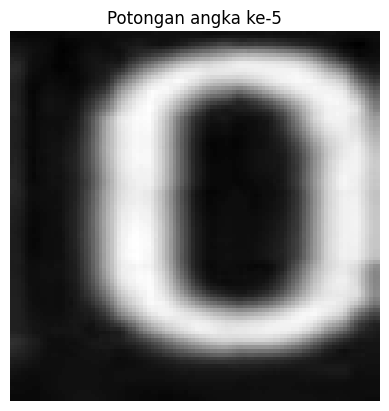

Prediksi utama: 8 (59.35%)
Alternatif:
Angka 8: 59.35%
Angka 1: 20.11%
Angka 9: 17.13%


In [50]:
import cv2
import numpy as np
import tensorflow as tf
import pickle
import os
import matplotlib.pyplot as plt

base = '/content/drive/MyDrive/PCVK/Gambar'
model = tf.keras.models.load_model(f'{base}/anpr.keras')

with open(f'{base}/kelas.pickle', 'rb') as f:
    kelas = pickle.load(f)

path = f'{base}/testing/ktm/05.jpg'
img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)

x = cv2.resize(img, (100, 100))
x = x.reshape(1, 100, 100, 1) / 255.0

pred = model.predict(x, verbose=0)[0]
urutan = np.argsort(pred)[::-1][:3]

plt.imshow(img, cmap='gray')
plt.title('Potongan angka ke-5')
plt.axis('off')
plt.show()

print('Prediksi utama:', kelas[urutan[0]], f'({pred[urutan[0]]:.2%})')
print('Alternatif:')
for i in urutan:
    print(f'Angka {kelas[i]}: {pred[i]:.2%}')

Berdasarkan hasil pengujian, model CNN memprediksi karakter pada potongan angka ke-5 sebagai angka 8 dengan tingkat keyakinan sebesar 59,35%. Prediksi alternatif yang dihasilkan adalah angka 1 sebesar 20,11% dan angka 9 sebesar 17,13%. Hasil ini menunjukkan bahwa model belum dapat mengenali seluruh karakter pada NIM dengan tepat karena terdapat perbedaan karakteristik antara data pengujian dan data pelatihan.

Ukuran gambar: (100, 100)


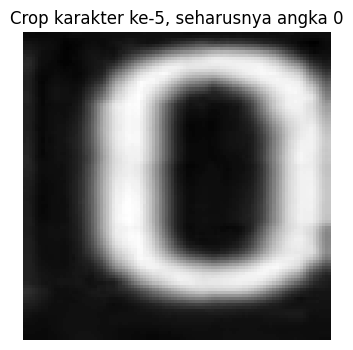

In [51]:
import cv2
import matplotlib.pyplot as plt

path = '/content/drive/MyDrive/PCVK/Gambar/testing/ktm/05.jpg'

img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)

if img is not None:
    print("Ukuran gambar:", img.shape)
    plt.figure(figsize=(4, 4))
    plt.imshow(img, cmap='gray')
    plt.title("Crop karakter ke-5, seharusnya angka 0")
    plt.axis('off')
    plt.show()
else:
    print("Gambar tidak ditemukan:", path)

In [52]:
import cv2
import numpy as np
import tensorflow as tf
import pickle

path = '/content/drive/MyDrive/PCVK/Gambar/testing/ktm/05.jpg'

model = tf.keras.models.load_model(
    '/content/drive/MyDrive/PCVK/Gambar/anpr.keras'
)

with open('/content/drive/MyDrive/PCVK/Gambar/kelas.pickle', 'rb') as f:
    kelas = pickle.load(f)

img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
img = cv2.resize(img, (100, 100))
img = img.reshape(1, 100, 100, 1) / 255.0

prediksi = model.predict(img, verbose=0)[0]
top3 = np.argsort(prediksi)[-3:][::-1]

print("Prediksi karakter ke-5:")
for i in top3:
    print(f"Angka {kelas[i]}: {prediksi[i] * 100:.2f}%")

Prediksi karakter ke-5:
Angka 8: 59.35%
Angka 1: 20.11%
Angka 9: 17.13%


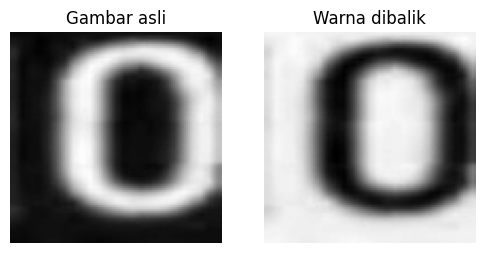


Prediksi Asli:
Angka 8: 59.35%
Angka 1: 20.11%
Angka 9: 17.13%

Prediksi Inversi:
Angka 0: 99.09%
Angka 6: 0.89%
Angka 7: 0.01%


In [53]:
import cv2
import numpy as np
import tensorflow as tf
import pickle
import matplotlib.pyplot as plt

path = '/content/drive/MyDrive/PCVK/Gambar/testing/ktm/05.jpg'
model = tf.keras.models.load_model(
    '/content/drive/MyDrive/PCVK/Gambar/anpr.keras'
)

with open('/content/drive/MyDrive/PCVK/Gambar/kelas.pickle', 'rb') as f:
    kelas = pickle.load(f)

img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
img = cv2.resize(img, (100, 100))

# Balik warna gambar
img_inverted = 255 - img

# Tampilkan gambar hasil preprocessing
plt.figure(figsize=(6, 3))

plt.subplot(1, 2, 1)
plt.imshow(img, cmap='gray')
plt.title('Gambar asli')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(img_inverted, cmap='gray')
plt.title('Warna dibalik')
plt.axis('off')

plt.show()

# Prediksi gambar asli dan gambar hasil inversi
for nama, gambar in [('Asli', img), ('Inversi', img_inverted)]:
    x = gambar.reshape(1, 100, 100, 1) / 255.0
    prediksi = model.predict(x, verbose=0)[0]
    top3 = np.argsort(prediksi)[-3:][::-1]

    print(f'\nPrediksi {nama}:')
    for i in top3:
        print(f'Angka {kelas[i]}: {prediksi[i] * 100:.2f}%')

In [56]:
import os
import cv2
import pickle
import numpy as np
import tensorflow as tf

data_dir_testing = "/content/drive/MyDrive/PCVK/Gambar/testing"
width, height = 100, 100

model = tf.keras.models.load_model(
    "/content/drive/MyDrive/PCVK/Gambar/anpr.keras"
)

with open("/content/drive/MyDrive/PCVK/Gambar/kelas.pickle", "rb") as f:
    dirs = pickle.load(f)

for car in sorted(os.listdir(data_dir_testing)):
    temp = ""
    folder = os.path.join(data_dir_testing, car)

    if not os.path.isdir(folder):
        continue

    for char_img in sorted(os.listdir(folder)):
        path = os.path.join(folder, char_img)
        img_array = cv2.imread(path, cv2.IMREAD_GRAYSCALE)

        if img_array is None:
            continue

        new_array = cv2.resize(img_array, (width, height))

        # Membalik warna gambar sebelum prediksi
        new_array = 255 - new_array

        new_array = new_array.reshape(
            -1, width, height, 1
        ) / 255.0

        prediction = model.predict(new_array, verbose=0)
        temp += dirs[np.argmax(prediction[0])]

    print("folder name: {} no: {}".format(car, temp))

folder name: ktm no: 243707020703


In [55]:
import os
import cv2
import pickle
import numpy as np
import tensorflow as tf

base = "/content/drive/MyDrive/PCVK/Gambar"
folder = os.path.join(base, "testing", "ktm")

model = tf.keras.models.load_model(os.path.join(base, "anpr.keras"))

with open(os.path.join(base, "kelas.pickle"), "rb") as f:
    kelas = pickle.load(f)

for nama in sorted(os.listdir(folder)):
    path = os.path.join(folder, nama)

    if not os.path.isfile(path):
        continue

    img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    if img is None:
        continue

    img = cv2.resize(img, (100, 100))
    asli = img.reshape(1, 100, 100, 1).astype("float32") / 255.0
    inversi = (255 - img).reshape(1, 100, 100, 1).astype("float32") / 255.0

    hasil_asli, hasil_inversi = model.predict(
        np.concatenate([asli, inversi], axis=0),
        verbose=0
    )

    a = kelas[np.argmax(hasil_asli)]
    b = kelas[np.argmax(hasil_inversi)]

    print(
        f"{nama}: asli={a} ({hasil_asli.max()*100:.1f}%), "
        f"inversi={b} ({hasil_inversi.max()*100:.1f}%)"
    )

01.jpg: asli=2 (100.0%), inversi=2 (100.0%)
02.jpg: asli=4 (91.9%), inversi=4 (67.6%)
03.jpg: asli=4 (94.4%), inversi=3 (81.9%)
04.jpg: asli=1 (90.5%), inversi=7 (68.6%)
05.jpg: asli=8 (59.4%), inversi=0 (99.1%)
06.jpg: asli=7 (99.2%), inversi=7 (100.0%)
07.jpg: asli=0 (99.7%), inversi=0 (99.4%)
08.jpg: asli=2 (99.9%), inversi=2 (100.0%)
09.jpg: asli=0 (98.1%), inversi=0 (58.7%)
10.jpg: asli=1 (98.9%), inversi=7 (90.2%)
11.jpg: asli=1 (93.5%), inversi=0 (64.6%)
12.jpg: asli=0 (99.1%), inversi=3 (97.2%)


### Kesimpulan

Berdasarkan praktikum yang telah dilakukan, CNN dapat digunakan untuk mengenali karakter angka pada KTM. Model berhasil dilatih dengan akurasi training 100% dan akurasi validasi 97,35%. Saat pengujian, pembalikan warna gambar dapat membantu mengenali angka tertentu, seperti angka 0 yang awalnya terbaca sebagai 8. Namun, cara ini tidak cocok untuk semua karakter karena masih ada beberapa angka yang salah dikenali. Hal ini menunjukkan bahwa kondisi gambar memengaruhi hasil pengenalan karakter.